# Model III
## Rozpoznawanie instrumentów za pomocą konwolucji (ResNet18)

### Biblioteki

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

from model import Resnet
from trening import get_device
from przygotowanie_danych import (
    INSTRUMENTS,
    create_datasets,
    create_loaders
)

In [3]:
learning_id = 1

In [4]:
results_dir = Path("wyniki")

# Wczytanie danych eksperymentu
results = pd.read_csv(results_dir / "modele.csv")

experiment = results.loc[
    results["Learning_ID"] == learning_id
].iloc[0]

# Pobranie wszystkich zapisanych parametrów
model_name = experiment["Model"]
dataset = experiment["Dataset"]
batch_size = int(experiment["Batch size"])
learning_rate = float(experiment["Learning rate"])
dropout = float(experiment["Dropout"])
best_epoch = int(experiment["Best epoch"])
best_val_loss = float(experiment["Best val loss"])
training_time = float(experiment["Training time [min]"])

# Wyświetlenie wszystkich danych
print("Parametry eksperymentu:")
print(f"Learning ID: {learning_id}")
print(f"Dataset: {dataset}")
print(f"Model: {model_name}")
print(f"Batch size: {batch_size}")
print(f"Learning rate: {learning_rate}")
print(f"Dropout: {dropout}")
print(f"Best epoch: {best_epoch}")
print(f"Best val loss: {best_val_loss}")
print(f"Training time: {training_time:.4f} min")

# Utworzenie i wczytanie modelu
device = get_device()
model = Resnet(dropout=dropout).to(device)

weights_file = results_dir / f"{learning_id}.pth"

model.load_state_dict(
    torch.load(weights_file, map_location=device, weights_only=True)
)

Parametry eksperymentu:
Learning ID: 1
Dataset: 1_1
Model: resnet18
Batch size: 32
Learning rate: 0.0001
Dropout: 0.3
Best epoch: 4
Best val loss: 0.3675631946153215
Training time: 7.2878 min


<All keys matched successfully>

In [5]:
train_dataset, val_dataset, test_dataset = create_datasets(dataset)

train_loader, val_loader, test_loader = create_loaders(train_dataset, val_dataset, test_dataset, batch_size=batch_size)

Wczytuję spektrogramy z: C:\Users\Wiktor\Documents\GitHub\instrument-recognition-project\spectrograms\1_1


Best Micro-F1: 0.8701 | Threshold: 0.2546
Best Macro-F1: 0.8683 | Threshold: 0.2537


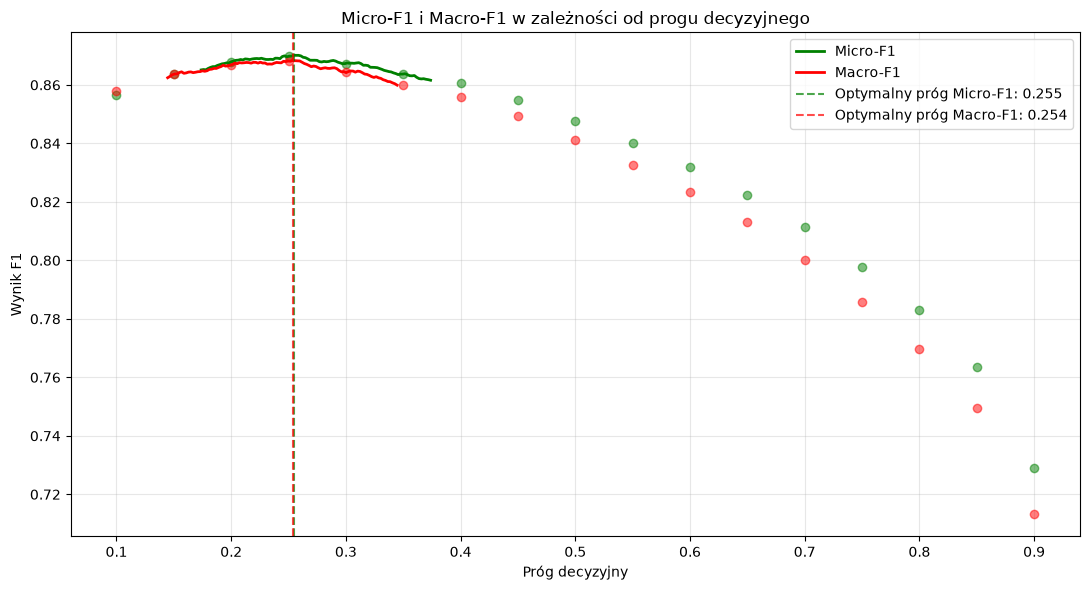

In [6]:
model.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)

        all_logits.append(torch.sigmoid(logits).cpu().numpy())
        all_labels.append(y.cpu().numpy())

all_probabilities = np.concatenate(all_logits, axis=0)
all_labels = np.concatenate(all_labels, axis=0)


def calculate_f1(threshold):
    predictions = (all_probabilities >= threshold).astype(float)

    micro = f1_score(
        all_labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro = f1_score(
        all_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return micro, macro


thresholds_coarse = np.linspace(0.1, 0.9, 17)

results_coarse = [
    calculate_f1(t) for t in thresholds_coarse
]

micro_coarse = np.array([r[0] for r in results_coarse])
macro_coarse = np.array([r[1] for r in results_coarse])

def estimate_maximum(thresholds, scores):
    a, b, c = np.polyfit(thresholds, scores, 2)

    if a < 0:
        estimated_threshold = -b / (2 * a)
    else:
        estimated_threshold = thresholds[np.argmax(scores)]

    return np.clip(estimated_threshold, 0.001, 0.999)



estimated_micro = estimate_maximum(thresholds_coarse, micro_coarse)
estimated_macro = estimate_maximum(thresholds_coarse, macro_coarse)

thresholds_micro = np.linspace(
    max(0.001, estimated_micro - 0.1),
    min(0.999, estimated_micro + 0.1),
    100
)

thresholds_macro = np.linspace(
    max(0.001, estimated_macro - 0.1),
    min(0.999, estimated_macro + 0.1),
    100
)

micro_fine = np.array([
    calculate_f1(t)[0] for t in thresholds_micro
])

macro_fine = np.array([
    calculate_f1(t)[1] for t in thresholds_macro
])

best_micro_idx = np.argmax(micro_fine)
best_macro_idx = np.argmax(macro_fine)

best_micro_threshold = thresholds_micro[best_micro_idx]
best_macro_threshold = thresholds_macro[best_macro_idx]

best_micro_f1 = micro_fine[best_micro_idx]
best_macro_f1 = macro_fine[best_macro_idx]

print(f"Best Micro-F1: {best_micro_f1:.4f} | Threshold: {best_micro_threshold:.4f}")
print(f"Best Macro-F1: {best_macro_f1:.4f} | Threshold: {best_macro_threshold:.4f}")

plt.figure(figsize=(11, 6))

plt.plot(
    thresholds_coarse,
    micro_coarse,
    "o",
    color="green",
    alpha=0.5
)

plt.plot(
    thresholds_coarse,
    macro_coarse,
    "o",
    color="red",
    alpha=0.5
)

plt.plot(
    thresholds_micro,
    micro_fine,
    color="green",
    linewidth=2,
    label="Micro-F1"
)

plt.plot(
    thresholds_macro,
    macro_fine,
    color="red",
    linewidth=2,
    label="Macro-F1"
)

plt.axvline(
    best_micro_threshold,
    color="green",
    linestyle="--",
    alpha=0.7,
    label=f"Optymalny próg Micro-F1: {best_micro_threshold:.3f}"
)

plt.axvline(
    best_macro_threshold,
    color="red",
    linestyle="--",
    alpha=0.7,
    label=f"Optymalny próg Macro-F1: {best_macro_threshold:.3f}"
)

plt.xlabel("Próg decyzyjny")
plt.ylabel("Wynik F1")
plt.title("Micro-F1 i Macro-F1 w zależności od progu decyzyjnego")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Optymalne threshold dla instrumentów:

Acoustic Guitar (steel): Threshold = 0.2863 | F1 = 0.8063
Alto Sax: Threshold = 0.1000 | F1 = 0.8935
Bright Acoustic Piano: Threshold = 0.1854 | F1 = 0.8563
Drums: Threshold = 0.4273 | F1 = 0.9937
Electric Bass (finger): Threshold = 0.3899 | F1 = 0.9363
Flute: Threshold = 0.1121 | F1 = 0.7251
String Ensemble 1: Threshold = 0.5072 | F1 = 0.9258

Micro-F1: 0.8751
Macro-F1: 0.8767


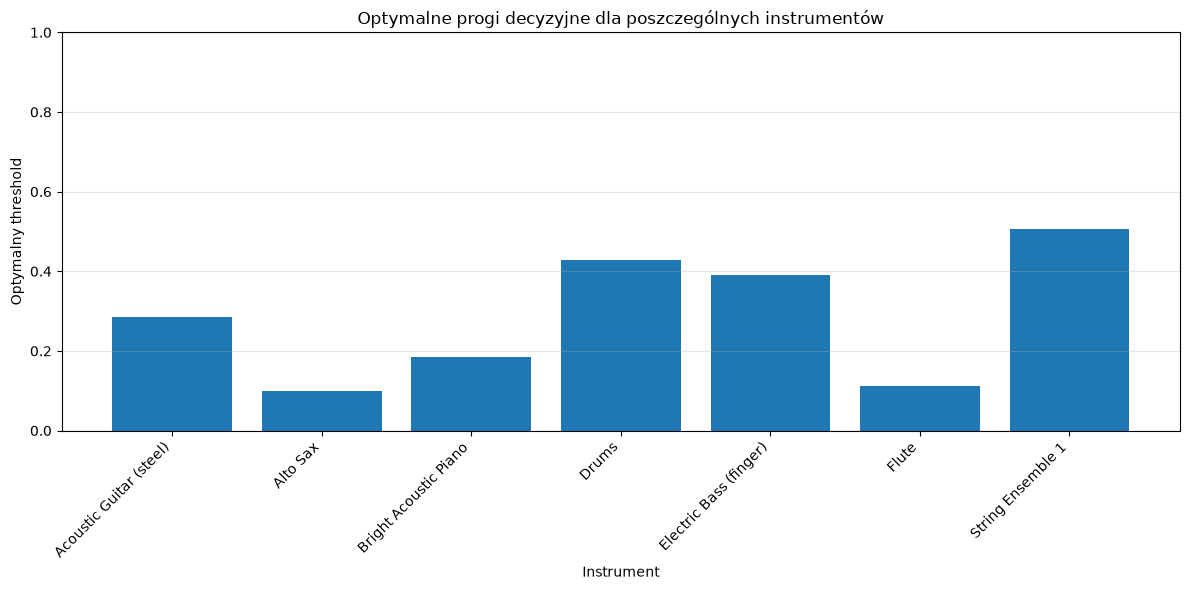

In [17]:
model.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)

        all_logits.append(torch.sigmoid(logits).cpu().numpy())
        all_labels.append(y.cpu().numpy())

all_probabilities = np.concatenate(all_logits, axis=0)
all_labels = np.concatenate(all_labels, axis=0)


# Nazwy instrumentów

class_names = list(INSTRUMENTS.keys())

num_classes = all_labels.shape[1]


# Funkcja F1 dla pojedynczego instrumentu

def calculate_class_f1(threshold, class_idx):

    predictions = (
        all_probabilities[:, class_idx] >= threshold
    ).astype(float)

    return f1_score(
        all_labels[:, class_idx],
        predictions,
        zero_division=0
    )


# Estymacja maksimum wielomianu drugiego stopnia

def estimate_maximum(thresholds, scores):

    a, b, c = np.polyfit(thresholds, scores, 2)

    if a < 0:
        estimated_threshold = -b / (2 * a)
    else:
        estimated_threshold = thresholds[np.argmax(scores)]

    return np.clip(estimated_threshold, 0.001, 0.999)


# Optymalizacja threshold dla każdego instrumentu

thresholds_coarse = np.linspace(0.1, 0.9, 17)

best_thresholds = np.zeros(num_classes)
best_f1_scores = np.zeros(num_classes)

all_thresholds_fine = []
all_f1_fine = []

for i in range(num_classes):

    # Przeszukiwanie wstępne

    f1_coarse = np.array([
        calculate_class_f1(t, i)
        for t in thresholds_coarse
    ])

    # Estymacja maksimum

    estimated_threshold = estimate_maximum(
        thresholds_coarse,
        f1_coarse
    )

    # Przeszukiwanie dokładne

    thresholds_fine = np.linspace(
        max(0.001, estimated_threshold - 0.1),
        min(0.999, estimated_threshold + 0.1),
        100
    )

    f1_fine = np.array([
        calculate_class_f1(t, i)
        for t in thresholds_fine
    ])

    # Wybór najlepszego progu

    best_idx = np.argmax(f1_fine)

    best_thresholds[i] = thresholds_fine[best_idx]
    best_f1_scores[i] = f1_fine[best_idx]

    all_thresholds_fine.append(thresholds_fine)
    all_f1_fine.append(f1_fine)


# Wyświetlenie optymalnych progów

print("Optymalne threshold dla instrumentów:\n")

for i, name in enumerate(class_names):

    print(
        f"{name}: Threshold = {best_thresholds[i]:.4f} | "
        f"F1 = {best_f1_scores[i]:.4f}"
    )


# Predykcje z indywidualnymi progami

predictions = (
    all_probabilities >= best_thresholds.reshape(1, -1)
).astype(float)


# Końcowe Micro-F1 i Macro-F1

micro_f1 = f1_score(
    all_labels,
    predictions,
    average="micro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    predictions,
    average="macro",
    zero_division=0
)

print(f"\nMicro-F1: {micro_f1:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")


# Wykres optymalnych progów

plt.figure(figsize=(12, 6))

plt.bar(
    class_names,
    best_thresholds
)

plt.xlabel("Instrument")
plt.ylabel("Optymalny threshold")
plt.title("Optymalne progi decyzyjne dla poszczególnych instrumentów")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


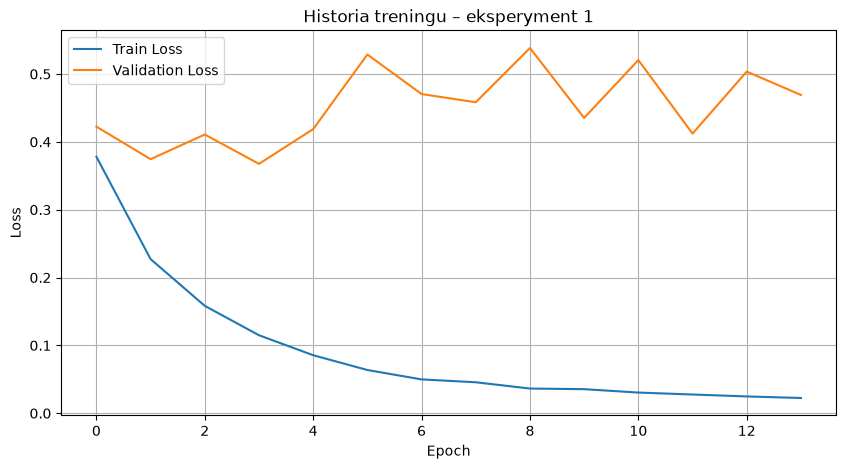

In [7]:
history = pd.read_csv(
    f"wyniki/history_{learning_id}.csv",
    index_col="epoch"
)

train_loss = history["train_loss"].tolist()
val_loss = history["val_loss"].tolist()

plt.figure(figsize=(10, 5))

plt.plot(history.index, train_loss, label="Train Loss")
plt.plot(history.index, val_loss, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"Historia treningu – eksperyment {learning_id}")
plt.legend()
plt.grid()
plt.show()

In [8]:
instrument_names = list(INSTRUMENTS.values())

criterion = nn.MultiLabelSoftMarginLoss()

model.eval()

all_predictions = []
all_labels = []

val_loss = 0.0

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)

        loss = criterion(logits, y)
        val_loss += loss.item() * X.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= best_macro_threshold).float()

        all_predictions.append(predictions.cpu().numpy())
        all_labels.append(y.cpu().numpy())

val_loss /= len(val_loader.dataset)

all_predictions = np.concatenate(all_predictions, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

f1_per_instrument = f1_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

precision_per_instrument = precision_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

recall_per_instrument = recall_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

metrics_macro_df = pd.DataFrame({
    "Instrument": instrument_names,
    "Precision": precision_per_instrument,
    "Recall": recall_per_instrument,
    "F1-score": f1_per_instrument
})

metrics_macro_df

,Instrument,Precision,Recall,F1-score
0,Gitara akustyczna,0.758780,0.855208,0.804114
1,Saksofon altowy,0.956522,0.802083,0.872521
2,Fortepian,0.870793,0.835417,0.852738
3,Perkusja,0.980533,0.996875,0.988636
4,Gitara basowa,0.917671,0.952083,0.934560
5,Flet,0.786335,0.659375,0.717280
6,Sekcja smyczkowa,0.873199,0.946875,0.908546


In [9]:
instrument_names = list(INSTRUMENTS.values())

model.eval()

all_predictions = []
all_labels = []

val_loss = 0.0

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)

        loss = criterion(logits, y)
        val_loss += loss.item() * X.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= best_micro_threshold).float()

        all_predictions.append(predictions.cpu().numpy())
        all_labels.append(y.cpu().numpy())

val_loss /= len(val_loader.dataset)

all_predictions = np.concatenate(all_predictions, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

f1_per_instrument = f1_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

precision_per_instrument = precision_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

recall_per_instrument = recall_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

metrics_micro_df = pd.DataFrame({
    "Instrument": instrument_names,
    "Precision": precision_per_instrument,
    "Recall": recall_per_instrument,
    "F1-score": f1_per_instrument
})

metrics_micro_df

,Instrument,Precision,Recall,F1-score
0,Gitara akustyczna,0.758780,0.855208,0.804114
1,Saksofon altowy,0.956522,0.802083,0.872521
2,Fortepian,0.871739,0.835417,0.853191
3,Perkusja,0.980533,0.996875,0.988636
4,Gitara basowa,0.917671,0.952083,0.934560
5,Flet,0.786335,0.659375,0.717280
6,Sekcja smyczkowa,0.873199,0.946875,0.908546


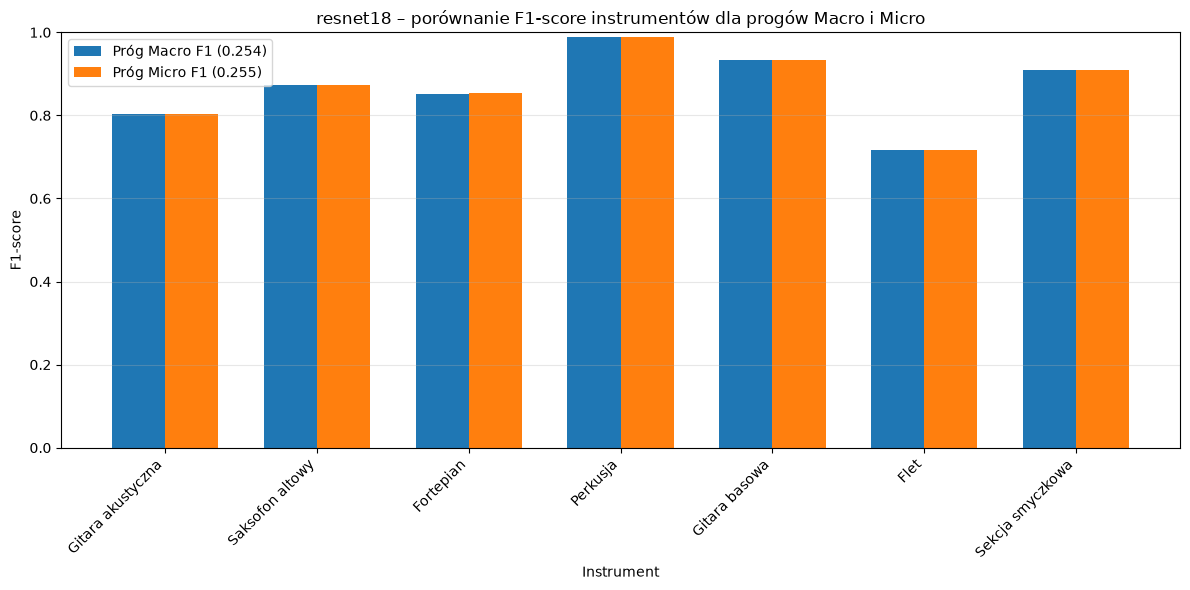

In [10]:
plt.figure(figsize=(12, 6))

x = np.arange(len(instrument_names))
width = 0.35

plt.bar(
    x - width / 2,
    metrics_macro_df["F1-score"],
    width,
    label=f"Próg Macro F1 ({best_macro_threshold:.3f})"
)

plt.bar(
    x + width / 2,
    metrics_micro_df["F1-score"],
    width,
    label=f"Próg Micro F1 ({best_micro_threshold:.3f})"
)

plt.xlabel("Instrument")
plt.ylabel("F1-score")
plt.title(f"{model_name} – porównanie F1-score instrumentów dla progów Macro i Micro")

plt.xticks(x, instrument_names, rotation=45, ha="right")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Zapis wyników

In [11]:
metrics_file = results_dir / "wyniki.csv"

processed_ids = (
    pd.read_csv(metrics_file)["Learning_ID"].tolist()
    if metrics_file.exists()
    else []
)

if learning_id not in processed_ids:

    f1_results = pd.DataFrame([{
        "Learning_ID": experiment["Learning_ID"],
        "Dataset": experiment["Dataset"],
        "Model": experiment["Model"],
        "Batch size": experiment["Batch size"],
        "Learning rate": experiment["Learning rate"],
        "Dropout": experiment["Dropout"],
        "Best epoch": experiment["Best epoch"],
        "Best val loss": experiment["Best val loss"],
        "Training time [min]": experiment["Training time [min]"],
        "Best Micro F1": best_micro_f1,
        "Best Micro threshold": best_micro_threshold,
        "Best Macro F1": best_macro_f1,
        "Best Macro threshold": best_macro_threshold
    }])

    f1_results.to_csv(
        metrics_file,
        mode="a",
        header=not metrics_file.exists(),
        index=False
    )

    print("Wyniki zapisane w wyniki.csv.")

else:
    print("Ten Learning_ID został już przetworzony. Pomijam zapis.")

Wyniki zapisane w wyniki.csv.
